In [1]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bootstrap

In [2]:
def ranked_probability_scores(observations, predictions):
    
    N = len(observations)
    rps = np.zeros(N)
    
    for i in range(N):
        
        observation_prob = np.array([0,0])
        observation_prob[observations[i]] = 1
            
        rps[i] = ( (np.cumsum(predictions[i])-np.cumsum(observation_prob))**2 ).sum()

    return rps

In [3]:
df_features = pd.read_csv('features/features_NE_week3_new.csv')
df_target = pd.read_csv('targets/northern_precipitation_90_cat.csv')

In [4]:
df_features['time'] = pd.to_datetime(df_features['time'])
df_features = df_features.set_index('time')

df_target['time'] = pd.to_datetime(df_target['time'])
df_target = df_target.set_index('time')

In [5]:
y_train = df_target[df_target.index < "2010-07"].values[:,0]
y_test = df_target[df_target.index >= "2010-07"].values[:,0]

In [6]:
drop = ['snow_depth', 'sea_ice_arctic', 'soil_moist_lower', 'nino3.4_index', 'MJO_phase', 'sea_ice_baka']
df_features_sel = df_features.drop(columns=drop)
len(df_features_sel.columns)

3

In [7]:
X_train = df_features_sel[df_features_sel.index < "2010-07"].values
X_test = df_features_sel[df_features_sel.index >= "2010-07"].values

In [8]:
classifier = RandomForestClassifier(n_estimators=1000, criterion='entropy', max_depth=None, min_samples_leaf=600, random_state=42)
classifier.fit(X_train, y_train)

y_pred = classifier.predict_proba(X_test)
rps = ranked_probability_scores(y_test, y_pred)

y_climpred = 0.9*np.ones((15*84, 2))
y_climpred[:,1] = 0.1
rps_clim = ranked_probability_scores(y_test, y_climpred)

print(rps.mean())
print(rps_clim.mean())

0.11156364258564438
0.11285714285714285


In [9]:
rpss = 100*(1-rps.mean()/rps_clim.mean())
print(rpss)

1.1461394810745928


In [2]:
rps_valid = 0.08828588371566105
rpss_valid = 100*(1-rps_valid/0.09)
print(rpss_valid)

1.9045736492654952


In [3]:
rps_valid_clim = 0.09026214111678059
rpss_valid_unbiased = 100*(1-rps_valid/rps_valid_clim)
print(rpss_valid_unbiased)

2.1894643498016175


In [11]:
rps_ann = rps.reshape((15,84)).mean(axis=1)
rps_clim_ann = rps_clim.reshape((15,84)).mean(axis=1)

In [12]:
def skill_score(score, ref_score, axis=-1):
    mean = np.mean(score, axis=axis)
    mean_ref = np.mean(ref_score, axis=axis)
    return 1 - mean/mean_ref

In [13]:
skill_score(rps_ann, rps_clim_ann)

np.float64(0.011461394810745928)

In [14]:
res = bootstrap((rps_ann, rps_clim_ann), skill_score, paired=True, confidence_level=0.90, rng=42)

In [15]:
res.confidence_interval

ConfidenceInterval(low=np.float64(-0.020401000390009267), high=np.float64(0.048640856735700684))

In [2]:
regions = ['Northern E.', 'Western-Central E.', 'Eastern E.', 'Southwestern E.']
skills = np.array([0.011461394810745928,-0.002648115461880929,0.002211686859834527,0.006375578228306367])*100
lower =  np.array([-0.020401000390009267,-0.023912903676852462,-0.007555371875750387,-0.011022201716741576])*100
upper =  np.array([0.048640856735700684,0.021610312599444625,0.011467987655843415,0.02201714340977614])*100

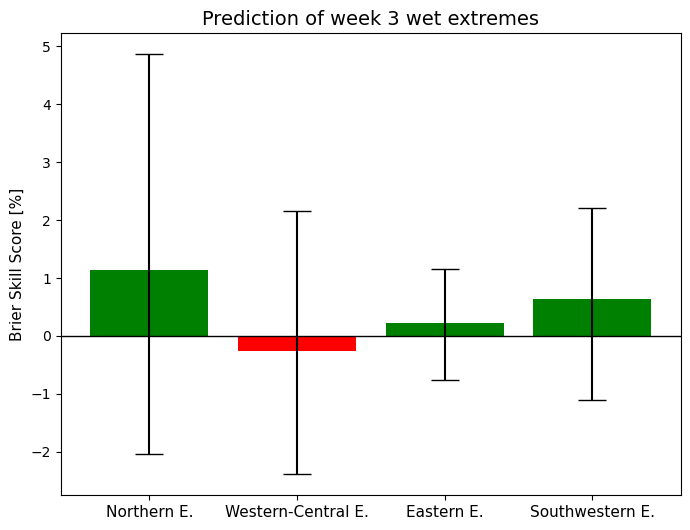

In [4]:
fig, ax = plt.subplots(figsize=(8,6))

ax.bar(regions, skills, yerr=np.stack((skills-lower, upper-skills)), capsize=10, color=['green','red','green','green']) 
ax.tick_params('x',labelsize=11)
ax.hlines(0, -0.6, 3.6, 'k', linewidths=1)
ax.set_xlim((-0.6, 3.6))
ax.set_ylabel('Brier Skill Score [%]', fontsize=11)
ax.set_title('Prediction of week 3 wet extremes', fontsize=14)
plt.savefig('wetextr_week3_bars.pdf', bbox_inches = 'tight')

0.0012935002714984621


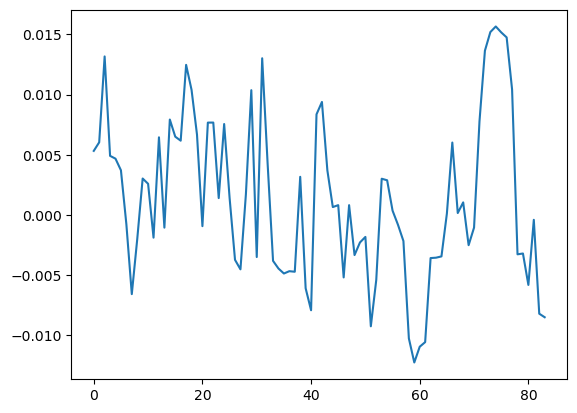

In [16]:
drps_cyc = rps_clim.reshape((15,84)).mean(axis=0) - rps.reshape((15,84)).mean(axis=0)
print(drps_cyc.mean())
plt.plot(drps_cyc)

In [17]:
lofo_rps = np.array([0.08844199040432338, 0.08882012138560844, 0.08893059923851755])
lofo_importances = lofo_rps - rps_valid
df_importances = pd.Series(
    lofo_importances, index=df_features_sel.columns
)

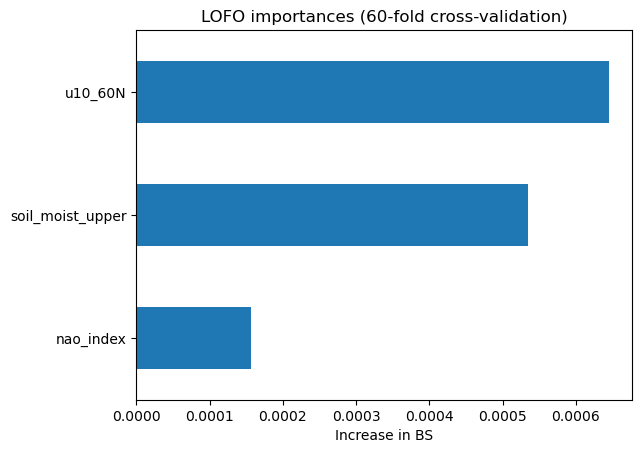

In [18]:
ax = df_importances.plot.barh()
ax.set_title("LOFO importances (60-fold cross-validation)")
ax.set_xlabel("Increase in BS")
plt.savefig('NE_wet_extr_lofo_valid.png', bbox_inches = 'tight')

In [19]:
lofo_rps_test = np.zeros(3)
for i in range(3):

    leave_out = df_features_sel.columns[i]
    df_features_new = df_features_sel.drop(columns=leave_out)
    X_train = df_features_new[df_features_new.index < "2010-07"].values
    X_test = df_features_new[df_features_new.index >= "2010-07"].values
    
    classifier = RandomForestClassifier(n_estimators=1000, criterion='entropy', max_depth=None, min_samples_leaf=600, random_state=42)
    classifier.fit(X_train, y_train)

    y_pred = classifier.predict_proba(X_test)
    rps = ranked_probability_scores(y_test, y_pred)
    lofo_rps_test[i] = rps.mean()

In [20]:
lofo_importances_test = lofo_rps_test - 0.11156364258564438
df_importances_test = pd.Series(
    lofo_importances_test, index=df_features_sel.columns
)

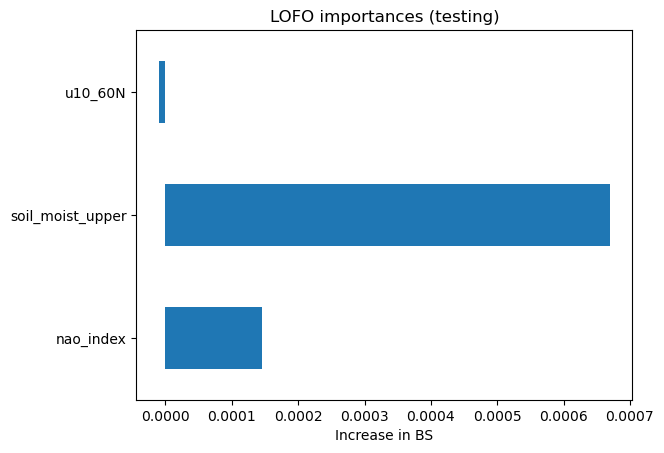

In [21]:
ax = df_importances_test.plot.barh()
ax.set_title("LOFO importances (testing)")
ax.set_xlabel("Increase in BS")
plt.savefig('NE_wet_extr_lofo_test.png', bbox_inches = 'tight')